In [1]:
import os
import pandas as pd
from pathlib import Path

# Ground truth Excel lives two levels up (ragV2/)
EXCEL_PATH = Path(__vsc_ipynb_file__).parent.parent.parent / 'Ground_Truth_Dataset_V2.xlsx'
df = pd.read_excel(EXCEL_PATH)

# Hold out one manual for out-of-distribution testing
ood_manual = 'Haas VF-2 Operator Manual'
ood  = df[ df['source_manual'].str.contains(ood_manual, na=False)]
rest = df[~df['source_manual'].str.contains(ood_manual, na=False)]

rest_shuffled = rest.sample(frac=1, random_state=42)
split_idx = int(len(rest_shuffled) * 0.7)

train = rest_shuffled[:split_idx]
test  = pd.concat([rest_shuffled[split_idx:], ood])

Path('datasets').mkdir(exist_ok=True)
train.to_excel('datasets/ground_truth_train.xlsx', index=False)
test.to_excel('datasets/ground_truth_test.xlsx',  index=False)
print(f'Train: {len(train)} | Test: {len(test)}')

Train: 44 | Test: 31


In [3]:
import sys, os
import pandas as pd
from pathlib import Path

# -- path setup --
_here     = Path(__vsc_ipynb_file__).parent.resolve()
_code_dir = (_here.parent.parent / 'CODE').resolve()
os.chdir(_code_dir)
for _p in [str(_code_dir), str(_here)]:
    if _p not in sys.path:
        sys.path.insert(0, _p)

from rag_retriever import RAGRetriever
from ga_reranker import GAReranker

retriever = RAGRetriever()
train_df  = pd.read_excel(_here / 'datasets/ground_truth_train.xlsx')

reranker = GAReranker()
reranker.train(
    collection=retriever.collection,
    embedding_model=retriever.embedding_model,
    training_data=train_df,
    ga_config={
        'population_size': 50,
        'max_generations': 100,
        'crossover_rate': 10,
        'mutation_rate': 6,
    },
    verbose=True,
)
Path(_here / 'trained_weights').mkdir(exist_ok=True)
reranker.save_weights(str(_here / 'trained_weights/best_weights.json'))

Loading embedding model...
Ready. Collection has 7599 documents.
Pre-retrieving chunks for all training questions...
FitnessEvaluator ready: 44 questions, 50 candidates each.

Baseline (cosine-only):
  NDCG: 0.5833 | P: 0.3000 | R: 0.5936 | MRR: 0.7285

Starting GA optimisation...

Gen    0 | Best: 0.6055 | Global: 0.6055 | Avg: 0.5821 | Step: 0.2000 | Restarts: 0
Gen   10 | Best: 0.6259 | Global: 0.6259 | Avg: 0.6235 | Step: 0.1809 | Restarts: 0
Gen   20 | Best: 0.6292 | Global: 0.6292 | Avg: 0.6265 | Step: 0.1636 | Restarts: 0
Gen   30 | Best: 0.6424 | Global: 0.6424 | Avg: 0.6379 | Step: 0.1479 | Restarts: 0
Gen   40 | Best: 0.6454 | Global: 0.6454 | Avg: 0.6451 | Step: 0.1338 | Restarts: 0
Gen   50 | Best: 0.6477 | Global: 0.6477 | Avg: 0.6476 | Step: 0.1210 | Restarts: 0
Gen   60 | Best: 0.6477 | Global: 0.6477 | Avg: 0.6477 | Step: 0.1094 | Restarts: 0
Gen   70 | Best: 0.6477 | Global: 0.6477 | Avg: 0.6477 | Step: 0.0990 | Restarts: 0
Gen   80 | Best: 0.6477 | Global: 0.6477 | Av

In [4]:
from pathlib import Path
_here   = Path(__vsc_ipynb_file__).parent.resolve()
test_df = pd.read_excel(_here / 'datasets/ground_truth_test.xlsx')

baseline  = reranker.evaluate(retriever.collection, retriever.embedding_model, test_df, use_weights=False)
ga_result = reranker.evaluate(retriever.collection, retriever.embedding_model, test_df, use_weights=True)

print(f"Baseline — NDCG: {baseline['ndcg']:.4f} | Precision: {baseline['precision']:.4f}")
print(f"GA       — NDCG: {ga_result['ndcg']:.4f} | Precision: {ga_result['precision']:.4f}")
print(f"Baseline — NDCG: {baseline['ndcg']:.4f} | P: {baseline['precision']:.4f} | R: {baseline['recall']:.4f} | MRR: {baseline['mrr']:.4f}")
print(f"GA       — NDCG: {ga_result['ndcg']:.4f} | P: {ga_result['precision']:.4f} | R: {ga_result['recall']:.4f} | MRR: {ga_result['mrr']:.4f}")

Baseline — NDCG: 0.4111 | Precision: 0.2516
GA       — NDCG: 0.6329 | Precision: 0.1548
Baseline — NDCG: 0.4111 | P: 0.2516 | R: 0.4266 | MRR: 0.5616
GA       — NDCG: 0.6329 | P: 0.1548 | R: 0.7097 | MRR: 0.7758


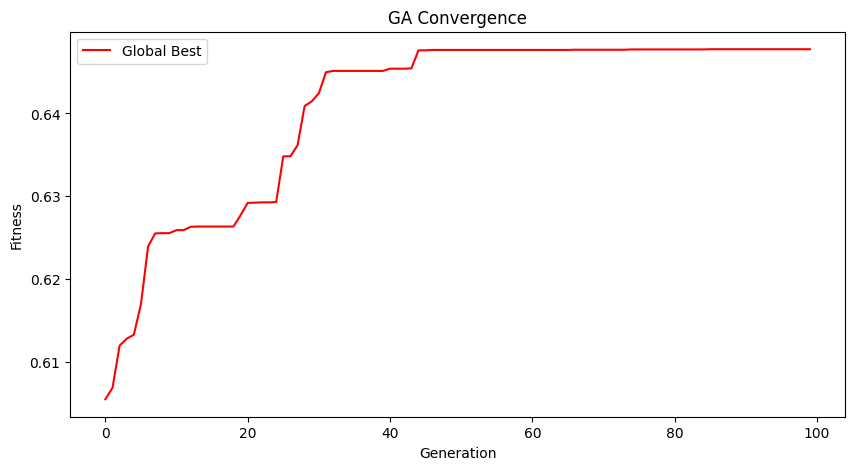

In [5]:
import matplotlib.pyplot as plt

history = reranker.ga_history
gens = [h["generation"] for h in history]
best = [h["global_best_fitness"] for h in history]
restarts = [h["generation"] for h in history if h["restart"]]

plt.figure(figsize=(10, 5))
plt.plot(gens, best, "r-", label="Global Best")
for r in restarts:
    plt.axvline(x=r, color="green", linestyle="--", alpha=0.5, label="Restart" if r == restarts[0] else "")
plt.xlabel("Generation")
plt.ylabel("Fitness")
plt.legend()
plt.title("GA Convergence")
_out = Path(__vsc_ipynb_file__).parent / 'evaluation/results'
_out.mkdir(parents=True, exist_ok=True)
plt.savefig(_out / 'convergence.png')
plt.show()